Groups customers by how they use the charging network, so that revenue and usage can be compared across segments. Customers are clustered by how often they charge, how many stations they use, how much energy they consume, and which chargers they prefer.   

Definitions used throughout:  

* **Customer:** a unique customer_id in the sessions table.
* **Frequency:** how foten a customer charges, measured as total sessions per active month.
* **Station reach:** the number of different stations a customer has sued.
* **Segment:** a group of customers with similar behaviour, found by clustering.
* **Silhouette score:** how well separated the clusters are, from -1 to 1 (higher is better).


**Set up**  
Libraries are imported, and the input path is set. show() saves every chart as a PNG in a figures folder (for the repo) and then displays it.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 50, 'axes.titlesize': 12, 'axes.labelsize': 10})

DATA_PATH = '/kaggle/input/datasets/sanyazuberi/ev-charging-raw-dataset/Copy of ev_charging_dataset.xlsx'
OUT = '/kaggle/working'
FIG_DIR = f'{OUT}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def show(name):
    """Save the current figure as a PNG (for the repo) and display it."""
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=100, bbox_inches='tight')
    plt.show()

**Loading the data**  
Only the sessions sheet is needed because it already holds the customer, station, region, charger type, energy, and cost for every session.

In [2]:
sessions = pd.read_excel(DATA_PATH, sheet_name='sessions')
sessions['start_timestamp'] = pd.to_datetime(sessions['start_timestamp'])

print(f"sessions: {len(sessions):,} | customers: {sessions['customer_id'].nunique():,}")

sessions: 294,024 | customers: 8,000


**Checking the data**  
Before building features,  the table was checked for missing values, the data range, and how many sessions each customer has. The spread in sessions per customer matters because it is the main way customers will differ.

In [3]:
print('Missing values:', int(sessions.isna().sum().sum()))
print('Date range:', sessions['start_timestamp'].min().date(), 'to', sessions['start_timestamp'].max().date())

per_cust = sessions.groupby('customer_id').size()
print('Sessions per customer (min / median / mean / max):',
      per_cust.min(), '/', per_cust.median(), '/', round(per_cust.mean(), 1), '/', per_cust.max())
print('Customers with exactly one session:', (per_cust == 1).sum())

Missing values: 0
Date range: 2022-01-01 to 2024-12-31
Sessions per customer (min / median / mean / max): 1 / 18.0 / 36.8 / 302
Customers with exactly one session: 2000


There are no missing values, and the data runs from 1 January 2022 to 31 December 2024. Customers have between 1 and 302 sessions (median 18, mean 36.8), and 2,000 customers have exactly one session.

**Building one row per customer**  
Every session is summarised into a customer-level table. Features fall into four groups: frequency (session, active months, recency), energy and value (kWh, duration, revenue), station preference (stations and regions used, share of visits to the favorite station), and timing (weekday, peak-hour, and night share). Recency is measured from the last day of data, 31 December 2024. Peak hours are 07-09h and 16-18h, the usual commuter windows

In [4]:
s = sessions.copy()
s['date']  = s['start_timestamp'].dt.normalize()
s['hour']  = s['start_timestamp'].dt.hour
s['dow']   = s['start_timestamp'].dt.dayofweek
s['month'] = s['start_timestamp'].dt.to_period('M')
s['is_weekday'] = (s['dow'] < 5).astype(int)
s['is_peak']    = s['hour'].isin([7, 8, 9, 16, 17, 18]).astype(int)
s['is_night']   = s['hour'].isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int)
SNAPSHOT = s['date'].max()          # reference date for recency

g = s.groupby('customer_id')
feat = pd.DataFrame({
    # frequency
    'sessions'      : g.size(),
    'active_days'   : g['date'].nunique(),
    'active_months' : g['month'].nunique(),
    'first_seen'    : g['date'].min(),
    'last_seen'     : g['date'].max(),
    # energy and value
    'kwh_total'     : g['energy_kwh'].sum(),
    'kwh_avg'       : g['energy_kwh'].mean(),
    'duration_avg'  : g['session_duration_minutes'].mean(),
    'revenue_total' : g['total_cost'].sum(),
    'ticket_avg'    : g['total_cost'].mean(),
    # station preference
    'n_stations'    : g['station_id'].nunique(),
    'n_regions'     : g['station_region'].nunique(),
    'top_station_share': g['station_id'].agg(lambda x: x.value_counts(normalize=True).iloc[0]),
    'top_region_share' : g['station_region'].agg(lambda x: x.value_counts(normalize=True).iloc[0]),
    # timing
    'weekday_share' : g['is_weekday'].mean(),
    'peak_share'    : g['is_peak'].mean(),
    'night_share'   : g['is_night'].mean(),
})
feat['tenure_days']  = (feat['last_seen'] - feat['first_seen']).dt.days
feat['recency_days'] = (SNAPSHOT - feat['last_seen']).dt.days
feat['sessions_per_month'] = feat['sessions'] / feat['active_months']
print(feat.shape)

(8000, 20)


**Adding charger, payment, and user-type mixes**  
For each customer, the share of their sessions on each charger type, each payment method, and each user_type is added.

In [5]:
for col, prefix in [('charger_type', 'share_'), ('payment_method', 'pay_'), ('user_type', 'ut_')]:
    mix = pd.crosstab(s['customer_id'], s[col], normalize='index').add_prefix(prefix)
    feat = feat.join(mix)

print(feat.shape)
feat[['sessions', 'sessions_per_month', 'n_stations', 'n_regions', 'kwh_avg',
      'duration_avg', 'ticket_avg', 'revenue_total', 'recency_days']].describe().T[['mean', '50%', 'min', 'max']].round(1)

(8000, 30)


,mean,50%,min,max
sessions,36.8,18.0,1.0,302.0
sessions_per_month,1.8,1.3,1.0,8.6
n_stations,14.1,13.0,1.0,33.0
n_regions,6.1,7.0,1.0,9.0
kwh_avg,47.6,46.9,23.9,80.0
duration_avg,34.6,34.9,15.0,60.0
ticket_avg,27.2,27.5,11.9,50.4
revenue_total,1021.4,503.0,11.9,8459.3
recency_days,271.0,26.0,0.0,1095.0


The customer table has 8,000 rows (one per customer) and 30 columns. A typical customer has 18 sessions (median), about 1.3 sessions per active month, and has used 13 stations. Average energy per session ranges from 24 to 80 kWh. Recency has a median of 26 days but a mean of 271, because the customers who charged only once last visited long ago.

**Do the assumed segments exist in the data?**  
The brief suggests four segments: high-frequency, commuters, public, and one-time. Before clustering, each was checked. Commuters would show weekday-heavy, peak-hour-heavy charging and a favourite station they keep returning to. A "public" segment would need a customer to keep the same user_type across sessions.

,customers,sessions,stations_used,favourite_station_share,weekday_share,peak_share
sessions,,,,,,
1 (one-time),2000,1.00,1.00,1.00,0.76,0.32
2-20,2858,16.28,12.43,0.16,0.77,0.33
21-40,1142,23.42,16.04,0.14,0.77,0.33
40+,2000,109.38,28.58,0.09,0.77,0.33


Repeat customers whose favourite station gets over half their visits: 0 of 5,999
Repeat customers with sessions under more than one user_type: 100%
Average share of a repeat customer's sessions in their main user_type: 0.35


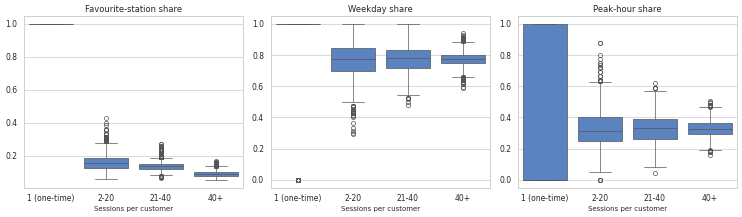

In [6]:
bands = pd.cut(feat['sessions'], [0, 1, 20, 40, 1000], labels=['1 (one-time)', '2-20', '21-40', '40+'])
display(feat.groupby(bands).agg(
    customers=('sessions', 'size'), sessions=('sessions', 'mean'), stations_used=('n_stations', 'mean'),
    favourite_station_share=('top_station_share', 'mean'),
    weekday_share=('weekday_share', 'mean'), peak_share=('peak_share', 'mean')).round(2))

rep = feat[feat['sessions'] > 5]
print(f"Repeat customers whose favourite station gets over half their visits: {(rep['top_station_share'] > 0.5).sum()} of {len(rep):,}")

n_types = s.groupby('customer_id')['user_type'].nunique()
print(f"Repeat customers with sessions under more than one user_type: {(n_types[rep.index] > 1).mean():.0%}")
ut = feat.filter(like='ut_')
print("Average share of a repeat customer's sessions in their main user_type:", round(ut.loc[rep.index].max(axis=1).mean(), 2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, col, t in zip(ax, ['top_station_share', 'weekday_share', 'peak_share'],
                     ['Favourite-station share', 'Weekday share', 'Peak-hour share']):
    sns.boxplot(x=bands, y=feat[col], ax=a, color='#4a7fd1')
    a.set_title(t); a.set_xlabel('Sessions per customer'); a.set_ylabel('')
show('01_segment_assumption_check')

Two of the four assumed segments are not supported. Weekday share (0.77) and peak-hour share (0.33) are the same in every frequency band, so no group behaves like commuters. Among the 5,999customers with more than 5 sessions, none sends over half their visits to one station, and the favorite station takes only 13% on average. The heavier the user, the more stations they spread across (about 29 stations for customers with over 40 sessions, against 12 for customers with 2-20 sessions).  
user_type is also not a customer attribute. Every repeat customer has sessions under more than one type, and their main type covers only 35% of their sessions, close to an even split across four types. It describes sessions, not people, so it cannot define a "public" segment.  
The clustering therefore uses frequency, station reach, energy, and charger preference. Timing and user_type are not used.

**Choosing the clustering features**  
Five features describe how customers differ: total sessions (log scale, because the counts are skewed), sessions per active month, stations used, average kWh per session, and the share of sessions on 300kW chargers. All are standardised so no feature dominates because of its scale. As a check, the timing features are added to see whether they help.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

feat['log_sessions'] = np.log1p(feat['sessions'])
CLUSTER_FEATURES = ['log_sessions', 'sessions_per_month', 'n_stations', 'kwh_avg', 'share_DC_300kW']
X = feat[CLUSTER_FEATURES]
Z = StandardScaler().fit_transform(X)

timing = feat[['weekday_share', 'peak_share', 'night_share']]
Z_timing = StandardScaler().fit_transform(pd.concat([X, timing], axis=1))

def sil(Zm, k=6):
    labels = KMeans(k, n_init=10, random_state=42).fit_predict(Zm)
    return silhouette_score(Zm, labels, sample_size=5000, random_state=1)

print(f'Silhouette (k=6), chosen features : {sil(Z):.3f}')
print(f'Silhouette (k=6), plus timing     : {sil(Z_timing):.3f}')
X.corr().round(2)

Silhouette (k=6), chosen features : 0.655
Silhouette (k=6), plus timing     : 0.452


,log_sessions,sessions_per_month,n_stations,kwh_avg,share_DC_300kW
log_sessions,1.00,0.72,0.97,-0.11,-0.07
sessions_per_month,0.72,1.00,0.73,-0.04,-0.03
n_stations,0.97,0.73,1.00,-0.09,-0.06
kwh_avg,-0.11,-0.04,-0.09,1.00,0.88
share_DC_300kW,-0.07,-0.03,-0.06,0.88,1.00


Adding the timing features reduces the silhouette score from 0.655 to 0.452, so they introduce noise and are excluded.  
Two pairs of chosen features are strongly related: total sessions and stations used (correlation 0.97), and average kWh and the 300 kW share (0.88). The first pair means frequency is counted twice, and the second means the energy-based separation is driven largely by the charger type. I kept this in mind when reading the personas.

**Choosing the number of clusters**  
K-means was run for 2 to 9 clusters. The elbow plot shows how much tighter the clusters get with each extra cluster, and the silhouette score shows how well separated they are. The k with the highest silhouette score is used.

Silhouette by k: {2: np.float64(0.434), 3: np.float64(0.537), 4: np.float64(0.587), 5: np.float64(0.631), 6: np.float64(0.655), 7: np.float64(0.557), 8: np.float64(0.515), 9: np.float64(0.499)}
Best k: 6


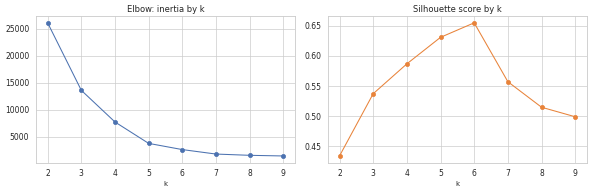

In [8]:
ks = list(range(2, 10))
inertia, sils = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=42).fit(Z)
    inertia.append(km.inertia_)
    sils.append(silhouette_score(Z, km.labels_, sample_size=5000, random_state=1))

best_k = ks[int(np.argmax(sils))]
print('Silhouette by k:', {k: round(v, 3) for k, v in zip(ks, sils)})
print('Best k:', best_k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, marker='o'); ax[0].set_title('Elbow: inertia by k'); ax[0].set_xlabel('k')
ax[1].plot(ks, sils, marker='o', color='#e8833a'); ax[1].set_title('Silhouette score by k'); ax[1].set_xlabel('k')
show('02_choosing_k')

The silhouette score rises to 0.655 at k=6. It drops to 0.557 at k=7, so the peak is clear. The elbow is less sharp but also flattens after k=6. K-Means with 6 clusters is used.

**Fitting K-Means and comparing with DBSCAN**  
The final K-Means model is fitted with k=6. DBSCAN, which needs no k and can flag outliers as noise, is run as a cross-check at three neighbour sizes (eps). The adjusted Rand index (ARI) measures how closely its groups match K-Means (1 means identical)

In [9]:
km = KMeans(best_k, n_init=10, random_state=42).fit(Z)
feat['cluster'] = km.labels_
print('Cluster sizes:', feat['cluster'].value_counts().sort_index().to_dict())

for eps in [0.3, 0.5, 0.8]:
    db = DBSCAN(eps=eps, min_samples=30).fit_predict(Z)
    n_cl = len(set(db)) - (1 if -1 in db else 0)
    print(f"eps={eps}: {n_cl} clusters, {(db == -1).sum()} noise points, ARI vs K-Means = {adjusted_rand_score(feat['cluster'], db):.2f}")

Cluster sizes: {0: 3987, 1: 1603, 2: 497, 3: 713, 4: 400, 5: 800}
eps=0.3: 5 clusters, 122 noise points, ARI vs K-Means = 0.93
eps=0.5: 4 clusters, 4 noise points, ARI vs K-Means = 0.57
eps=0.8: 4 clusters, 0 noise points, ARI vs K-Means = 0.57


The six K-Means clusters have 3,987, 1,603, 497, 713, 400, and 800 customers. With a tight eps of 0.3, DBSCAN finds 5 clusters that closely match K-Means (ARI 0.93) but labels 122 customers as noise. At wider settings, it merges clusters (4 groups, ARI 0.57). Because K-Means assigns every customer and DBSCAN broadly agrees, K-Means with 6 clusters is the final model.

**Profiling the clusters and naming the personas**  
Each cluster is profiled on its bevaiour. Names come from a rule applied to the profile, not from cluster numbers, so they stay correct if the numbering changes between runs. Repeat customers are ranked by sessions (Steady Regular, Frequent Chargers, Power Users). The three one-time clusters are split by charger: the one on300 kW chargers is Fast-Charge, and the other two are ranked by energy per session. 

In [10]:
profile = feat.groupby('cluster').agg(
    customers=('sessions', 'size'), sessions=('sessions', 'mean'), sessions_per_month=('sessions_per_month', 'mean'),
    stations_used=('n_stations', 'mean'), regions_used=('n_regions', 'mean'), kwh_avg=('kwh_avg', 'mean'),
    duration_avg=('duration_avg', 'mean'), ticket_avg=('ticket_avg', 'mean'), dc300_share=('share_DC_300kW', 'mean'),
    recency_days=('recency_days', 'mean'), revenue_per_customer=('revenue_total', 'mean')).round(2)

def name_segments(p):
    names = {}
    repeat = p[p['sessions'] > 1.5].sort_values('sessions')
    for cid, nm in zip(repeat.index, ['Steady Regulars', 'Frequent Chargers', 'Power Users']):
        names[cid] = nm
    one = p[p['sessions'] <= 1.5]
    fast = one['dc300_share'].idxmax()
    names[fast] = 'One-Time Fast-Charge Visitors'
    rest = one.drop(fast).sort_values('kwh_avg', ascending=False)
    for cid, nm in zip(rest.index, ['One-Time Standard Visitors', 'One-Time Slow-Charge Visitors']):
        names[cid] = nm
    return names

SEG = name_segments(profile)
feat['segment'] = feat['cluster'].map(SEG)

SEG_ORDER = ['Power Users', 'Frequent Chargers', 'Steady Regulars',
             'One-Time Fast-Charge Visitors', 'One-Time Standard Visitors', 'One-Time Slow-Charge Visitors']
PALETTE = dict(zip(SEG_ORDER, ['#e8833a', '#1f9d8a', '#4a7fd1', '#c9a227', '#9b6bc2', '#8a949c']))

profile.index = profile.index.map(SEG)
profile.index.name = 'segment'
profile = profile.loc[SEG_ORDER]
profile.T

segment,Power Users,Frequent Chargers,Steady Regulars,One-Time Fast-Charge Visitors,One-Time Standard Visitors,One-Time Slow-Charge Visitors
customers,400.00,1603.00,3987.00,497.00,713.00,800.00
sessions,257.50,72.27,18.33,1.00,1.02,1.07
sessions_per_month,7.28,2.60,1.35,1.00,1.00,1.00
stations_used,32.81,27.51,13.47,1.00,1.02,1.06
regions_used,9.00,8.90,7.28,1.00,1.01,1.04
kwh_avg,47.01,46.94,46.88,75.97,49.27,33.30
duration_avg,35.13,35.09,35.09,19.45,24.72,48.97
ticket_avg,27.82,27.84,27.74,38.68,25.29,17.10
dc300_share,0.21,0.20,0.20,1.00,0.00,0.00
recency_days,2.08,8.10,34.83,1008.08,1001.46,1000.49


The six clusters become six personas:

| Persona | Customers | Behaviour |
|---|---|---|
| Power Users | 400 | About 258 sessions each, 7.3 per active month, 33 stations across all 9 regions, last seen about 2 days before the end of the data. Revenue per customer is 7,163. |
| Frequent Chargers | 1,603 | About 72 sessions, 2.6 per month, 28 stations, last seen about 8 days before the end. Revenue per customer is 2,012. |
| Steady Regulars | 3,987 | About 18 sessions, 1.4 per month, 13 stations, last seen about 35 days before the end. Revenue per customer is 509. |
| One-Time Fast-Charge Visitors | 497 | One session on a 300 kW charger: 76 kWh in 19 minutes, the highest ticket of the one-time groups (38.7). |
| One-Time Standard Visitors | 713 | One session on a 150 kW charger: 49 kWh in 25 minutes (ticket 25.3). |
| One-Time Slow-Charge Visitors | 800 | One session on a 50 kW charger: 33 kWh in 49 minutes, the lowest ticket (17.1). |

The three repeat personas differ only in how often and how widely they charge. Their energy per session (47 kWh), duration (35 minutes) and ticket (about 27.8) are almost the same. The three one-time personas differ only in the charger used for their single session, so they are best treated as one group.

**Seeing the segments**  
The clustering features are reduced to two dimensions with PCA to show how the segments sit relative to each other.

Variance explained by PC1, PC2: [0.531 0.37 ]


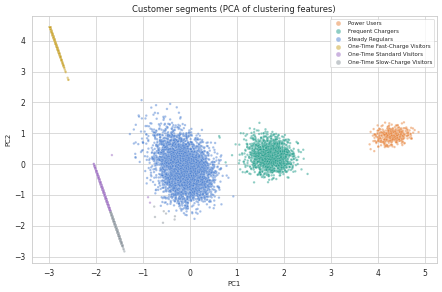

In [11]:
from sklearn.decomposition import PCA

pca = PCA(2, random_state=42)
P = pca.fit_transform(Z)
print('Variance explained by PC1, PC2:', pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(9, 6))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=feat['segment'].values, hue_order=SEG_ORDER,
                palette=PALETTE, s=12, alpha=0.5)
plt.title('Customer segments (PCA of clustering features)')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(fontsize=8, markerscale=2)
show('03_segments_pca')

The first two components explain 90% of the variance (53% and 37%), so the plot is a faithful picture. The three repeat tiers form separate bands ordered by frequency, and the three one-time groups form three tight, separate blobs.

**Segment revenue**  
Customers, sessions, energy, and revenue are totaled for each segment, with each segment's share of the total and its revenue per customer. The revenue share from the top 20% of customers is also checked. Finally, the dates of the one-time customers' sessions are checked.

In [12]:
seg = feat.groupby('segment').agg(
    customers=('sessions', 'size'), sessions=('sessions', 'sum'),
    kwh=('kwh_total', 'sum'), revenue=('revenue_total', 'sum')).loc[SEG_ORDER]
for c in ['customers', 'sessions', 'kwh', 'revenue']:
    seg[f'{c}_pct'] = (seg[c] / seg[c].sum() * 100).round(1)
seg['revenue_per_customer'] = (seg['revenue'] / seg['customers']).round(0)
display(seg.round(1))

r = feat['revenue_total'].sort_values(ascending=False)
print(f"Top 20% of customers generate {r.head(int(len(r) * 0.2)).sum() / r.sum():.1%} of revenue")

one = feat[feat['sessions'] == 1]
print('One-time customers charged between', one['first_seen'].min().date(), 'and', one['first_seen'].max().date())

,customers,sessions,kwh,revenue,customers_pct,sessions_pct,kwh_pct,revenue_pct,revenue_per_customer
segment,,,,,,,,,
Power Users,400,103001,4842666.4,2865391.3,5.0,35.0,35.1,35.1,7163.0
Frequent Chargers,1603,115845,5437388.1,3225275.0,20.0,39.4,39.4,39.5,2012.0
Steady Regulars,3987,73099,3426528.1,2027950.6,49.8,24.9,24.8,24.8,509.0
One-Time Fast-Charge Visitors,497,497,37755.7,19225.8,6.2,0.2,0.3,0.2,39.0
One-Time Standard Visitors,713,727,35759.8,18406.1,8.9,0.2,0.3,0.2,26.0
One-Time Slow-Charge Visitors,800,855,28647.7,14851.4,10.0,0.3,0.2,0.2,19.0


Top 20% of customers generate 66.2% of revenue
One-time customers charged between 2022-01-01 and 2022-06-28


The three repeat personas account for 99.4% of revenue (total 8.17 million): Frequent Chargers (36.5%), Power Users (35.1%), and Steady Regulars (24.8%). Power Users are only 5% of customers but earn 14 times as much per customer as Steady Regulars (7,163 vs 509). The top 20% of customers generate 66.2% of revenue.  
The three one-time groups are 25% of customers but only 0.6% of revenue between them.  
All one-time customers made their single session between 1 January and 28 June 2022. They are an early-2022 group that never came back, not a steady flow of new visitors. Their lack of a second visit has gone unrecovered for over two and a half years.

**Revenue share and revenue over time**  
The first chart compares each segment's share of customers with its share of revenue. The second shows monthly revenue stacked by segment.

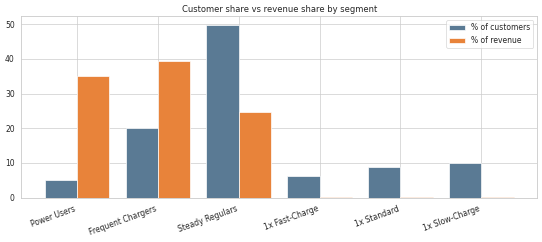

segment,Power Users,Frequent Chargers,Steady Regulars,One-Time Fast-Charge Visitors,One-Time Standard Visitors,One-Time Slow-Charge Visitors
month,,,,,,
2022,363673.0,360874.0,253302.0,19226.0,17948.0,13750.0
2023,907590.0,1038410.0,641265.0,0.0,96.0,414.0
2024,1594128.0,1825991.0,1133384.0,0.0,363.0,688.0


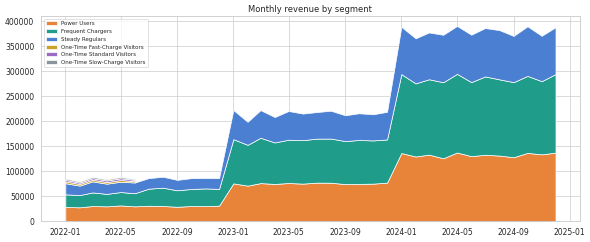

In [13]:
short = [n.replace(' Visitors', '').replace('One-Time ', '1x ') for n in SEG_ORDER]
x = np.arange(len(SEG_ORDER)); w = 0.4
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - w / 2, seg['customers_pct'], w, label='% of customers', color='#5a7a94')
ax.bar(x + w / 2, seg['revenue_pct'], w, label='% of revenue', color='#e8833a')
ax.set_xticks(x); ax.set_xticklabels(short, rotation=20, ha='right')
ax.set_title('Customer share vs revenue share by segment'); ax.legend()
show('04_customers_vs_revenue')

s2 = s.merge(feat[['segment']], left_on='customer_id', right_index=True)
monthly = s2.groupby([s2['month'].dt.to_timestamp(), 'segment'])['total_cost'].sum().reset_index()
mp = monthly.pivot(index='month', columns='segment', values='total_cost')[SEG_ORDER]
display(mp.groupby(mp.index.year).sum().round(0))

fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(mp.index, mp.T.values, labels=SEG_ORDER, colors=[PALETTE[n] for n in SEG_ORDER])
ax.legend(loc='upper left', fontsize=8); ax.set_title('Monthly revenue by segment')
show('05_monthly_revenue')

The bar chart shows how concentrated the revenue is. Steady Regulars make up 50% of customers but generate 25% of revenue, while the top two tiers, which make up 25% of customers, generate 75%.  
Total revenue grew from about 1.03 million in 2022 to 2.59 million in 2023 and 4.55 million in 2024. Within each year, monthly revenue is nearly flat, then jumps at the start of the next year. theone-time groups appear only in early 2022 and contribute almost nothing afterward, so all growth after 2022 comes from the three repeat tiers.



**Usage Patterns**  
Three views of how each segment uses the network: the hour of day, the regions, and the charger types.

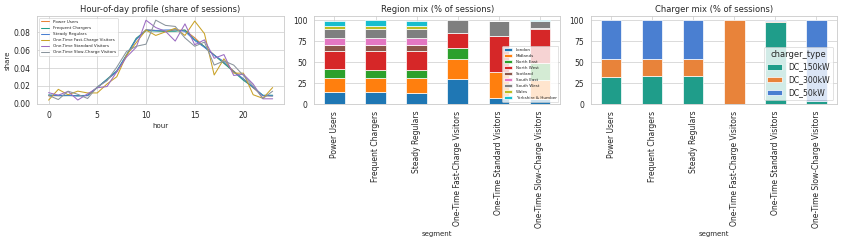

station_region,London,Midlands,North East,North West,Scotland,South East,South West,Wales,Yorkshire & Humber
segment,,,,,,,,,
Power Users,13.9,17.3,10.4,22.3,6.8,8.5,10.2,3.5,7.0
Frequent Chargers,13.9,17.1,10.2,22.2,7.0,8.8,10.3,3.5,7.0
Steady Regulars,13.8,17.0,10.4,22.3,7.0,8.5,10.4,3.4,7.0
One-Time Fast-Charge Visitors,30.6,23.3,13.5,17.5,0.0,0.0,15.1,0.0,0.0
One-Time Standard Visitors,7.4,30.5,0.3,43.6,0.1,0.0,17.6,0.1,0.3
One-Time Slow-Charge Visitors,6.1,22.6,20.7,40.8,0.6,0.6,7.4,0.5,0.8


charger_type,DC_150kW,DC_300kW,DC_50kW
segment,,,
Power Users,32.7,20.7,46.6
Frequent Chargers,33.1,20.4,46.5
Steady Regulars,33.1,20.3,46.6
One-Time Fast-Charge Visitors,0.0,100.0,0.0
One-Time Standard Visitors,98.6,0.1,1.2
One-Time Slow-Charge Visitors,4.1,0.0,95.9


In [14]:
hr = s2.groupby(['segment', 'hour']).size().reset_index(name='n')
hr['share'] = hr['n'] / hr.groupby('segment')['n'].transform('sum')
reg = pd.crosstab(s2['segment'], s2['station_region'], normalize='index').mul(100).round(1).loc[SEG_ORDER]
chg = pd.crosstab(s2['segment'], s2['charger_type'], normalize='index').mul(100).round(1).loc[SEG_ORDER]

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.lineplot(data=hr, x='hour', y='share', hue='segment', hue_order=SEG_ORDER, palette=PALETTE, ax=ax[0])
ax[0].set_title('Hour-of-day profile (share of sessions)'); ax[0].legend(fontsize=6)
reg.plot(kind='bar', stacked=True, ax=ax[1], colormap='tab10')
ax[1].set_title('Region mix (% of sessions)'); ax[1].legend(fontsize=6)
chg.plot(kind='bar', stacked=True, ax=ax[2], color=['#1f9d8a', '#e8833a', '#4a7fd1'])
ax[2].set_title('Charger mix (% of sessions)')
show('06_usage_patterns')
display(reg); display(chg)

The three repeat personas have the same usage pattern. Their hourly profiles overlap almost exactly (each hour's share is between about 1% and 8% of sessions), and their region mix is the same (North West about 22%, Midlands 17%, London 14%). They also use the same charger mix (about 47% on 50 kW and 20% on 300 kW). Segments differ in how much customers charge, not where, when, or on which charger.  
The one-time groups look different, but each customer made a single session, so their mix mostly reflects the one charger used: 100% of the Fast-Charge group used 300 kW, 99% of the Standard groups used 150 kW, and 96% of the Slow-Charge group used 50 kW.

**Do the used behaviour carry segment information?**  
If timing, payment method, or user_type  held hidden information about segments, an XGBoost classifier trained only on them should beat simply guessing the biggest segment. This checks the segmentation, not the forecast. It is run on repeat customers only.  
Shares like "% weekday" are noisy for customers with few sessions and tight for customers with many, so a model can tell heavy users apart from how close a share sits to the average. The first run uses all sessions, and the second uses exactly 15 randomly chosen sessions per customer, so that the noise is the same for everyone. 

In [15]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(5, shuffle=True, random_state=42)

def make_model():
    return XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                         n_jobs=-1, random_state=42, eval_metric='mlogloss')

# (a) naive: shares computed from all of a customer's sessions
rep = feat[feat['sessions'] > 1.5]
unused = ['weekday_share', 'peak_share', 'night_share'] + [c for c in feat if c.startswith(('pay_', 'ut_'))]
y = rep['segment'].astype('category').cat.codes
acc_naive = cross_val_score(make_model(), rep[unused], y, cv=cv).mean()
base_naive = y.value_counts(normalize=True).max()
print(f'(a) naive      : accuracy {acc_naive:.3f} | baseline {base_naive:.3f}')

# (b) controlled: exactly N sessions per customer
N = 15
eligible = feat[feat['sessions'] >= N].index
ss = s[s['customer_id'].isin(eligible)].groupby('customer_id', group_keys=False).sample(N, random_state=42)
Xc = (ss.groupby('customer_id')[['is_weekday', 'is_peak', 'is_night']].mean()
        .join(pd.crosstab(ss['customer_id'], ss['payment_method'], normalize='index'))
        .join(pd.crosstab(ss['customer_id'], ss['user_type'], normalize='index')))
yc = feat.loc[Xc.index, 'segment'].astype('category').cat.codes
acc_ctrl = cross_val_score(make_model(), Xc, yc, cv=cv).mean()
base_ctrl = yc.value_counts(normalize=True).max()
print(f'(b) controlled : accuracy {acc_ctrl:.3f} | baseline {base_ctrl:.3f}')

validation = pd.DataFrame({'test': ['naive (all sessions)', 'controlled (15 sessions each)'],
                           'customers': [len(rep), len(Xc)],
                           'xgboost_accuracy': [round(acc_naive, 3), round(acc_ctrl, 3)],
                           'majority_baseline': [round(base_naive, 3), round(base_ctrl, 3)]})
validation

(a) naive      : accuracy 0.899 | baseline 0.664
(b) controlled : accuracy 0.607 | baseline 0.620


,test,customers,xgboost_accuracy,majority_baseline
0,naive (all sessions),6000,0.899,0.664
1,controlled (15 sessions each),5270,0.607,0.620


The naive test scores 0.90 against a baseline of 0.66, which looks strong but is misleading: it comes from the noise effect described above, not from real behavior. In the controlled test (5,270 customers with at least 15 sessions), accuracy is 0.61, slightly below the 0.62 baseline. Timing, payment method, and user_type therefore carry no information about the segment. Segments are defined by how often, how widely, and how much customers charge, and not by when or how they pay.

**Saving the outputs**  
The customer-level table and every summary table are saved as CSVs. They feed the dashboard, so no calculations need to be repeated there.

In [16]:
feat.drop(columns=['cluster']).to_csv(f'{OUT}/customer_features_segments.csv')
profile.to_csv(f'{OUT}/segment_profiles.csv')
seg.to_csv(f'{OUT}/segment_revenue_usage.csv')
monthly.to_csv(f'{OUT}/monthly_revenue_by_segment.csv', index=False)
hr.to_csv(f'{OUT}/hourly_profile_by_segment.csv', index=False)
reg.to_csv(f'{OUT}/region_mix_by_segment.csv')
chg.to_csv(f'{OUT}/charger_mix_by_segment.csv')
validation.to_csv(f'{OUT}/model_validation.csv', index=False)

print(sorted(f for f in os.listdir(OUT) if f.endswith('.csv')))

['charger_mix_by_segment.csv', 'customer_features_segments.csv', 'hourly_profile_by_segment.csv', 'model_validation.csv', 'monthly_revenue_by_segment.csv', 'region_mix_by_segment.csv', 'segment_profiles.csv', 'segment_revenue_usage.csv']
